# Assignment 3: Sampling Distributions and Estimation
Authored by Kristian M. P. Dashnaw (344849) & Katrine B. Aamand (344848) <br>
Based on assignment 3 description (https://rbrooksdk.github.io/STA1_26/assignments/assignment_03_sampling_and_estimation/)

## Table of Contents

1. **Part 1 — Sampling distributions and the CLT**
    - 1.1 Simulated Sample Means and Summary Table
    - 1.2 Sampling Distributions with Normal Overlays
    - 1.3 Tail Probability $P(\bar X>75)$: Simulation vs. CLT
    - 1.4 Smallest $n$ with $\operatorname{SE}(\bar X)\le6$ Minutes
    - 1.5 Running Mean and the Law of Large Numbers
    - CLT Scope Statement
2. **Part 2 — Estimating mean sensor error**
    - 2.1 Summary Statistics and Standard Error
    - 2.2 Histogram, QQ-Plot, and $t$-Interval Suitability
    - 2.3 95% $t$ Interval: Components and SciPy Verification
    - 2.4 90%, 95%, and 99% $t$ Intervals and Widths
    - 2.5 Sample-Size Planning for a 0.10 °C Margin of Error
    - 2.6 Percentile Bootstrap Interval
3. **Part 3 — Estimating a false-rejection proportion**
    - 3.1 Sample Size, False Rejections, and $\hat p$
    - 3.2 95% Wilson Interval
    - 3.3 95% Wald Interval and Comparison with Wilson
    - 3.4 90%, 95%, and 99% Wilson Intervals and Widths
    - 3.5 Sample-Size Planning for a 0.02 Margin of Error
4. **Part 4 — AI-Use and Conclusion**
    - AI-Use Statement
    - Overall Conclusion

## Working Notes

**How to present the work (from the assignment description):**

> Use executed code for every simulation, estimate, interval, table, and plot. Use Markdown for model statements, formulas, assumptions, coverage interpretations, and conclusions. Show requested interval components before verifying with a library function.

In [161]:
#Imports:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from scipy.stats import probplot, t, bootstrap
from scipy import stats

# Load the data files:
print("\nSensor_Calibration.csv, first 5 rows:")
sensorCalibrationData_unmodified = pd.read_csv('data/assignment03_sensor_calibration.csv', delimiter = ',')
display(sensorCalibrationData_unmodified.head(5))

print("\n\nAccess_Control.csv, first 5 rows:")
accessControlData_unmodified = pd.read_csv('data/assignment03_access_control.csv', delimiter = ',')
display(accessControlData_unmodified.head(5))


Sensor_Calibration.csv, first 5 rows:


,sensor_id,calibration_error_c
0,1,0.334
1,2,0.383
2,3,1.644
3,4,0.627
4,5,0.615




Access_Control.csv, first 5 rows:


,attempt_id,false_reject
0,1,0
1,2,0
2,3,0
3,4,1
4,5,0


<br><br><br>

---

<br><br>

## Part 1: Sampling distributions and the CLT

Restoration time in a service system is modelled as exponential with population mean and standard deviation $\mu=\sigma=60$ minutes. Use this known population model and NumPy's random generator with seed 2026 and at least 20,000 repetitions per sample size.

<br><br>

<br>

### 1.1 Simulate samples for $n=1,5,20,80$ and store their means. Create a table with $n$, theoretical mean, simulated mean of means, theoretical standard error $\sigma/\sqrt n$, and empirical standard deviation of the simulated means.

In [162]:
# TODO: Katrine

<br><br>
### 1.2 Create one figure showing the four sampling distributions with density histograms and overlay $N(\mu,\sigma^2/n)$. Explain how centre, spread, and shape change and why the normal curve is an approximation for this non-normal population.

In [163]:
# TODO: Katrine

<br><br>
### 1.3 For $n=20$ and $n=80$, estimate $P(\bar X>75)$ by simulation and calculate the CLT approximation. Compare the values.

In [164]:
# TODO: Katrine

<br><br>
### 1.4 Find the smallest integer $n$ for which $\operatorname{SE}(\bar X)\le6$ minutes and verify it by simulation.


In [165]:
# TODO: Katrine

<br><br>

### 1.5 Generate one sequence of 5,000 observations and plot its running mean. Explain the law of large numbers and how this plot differs from a sampling distribution.

In [166]:
# TODO: Katrine

### CLT Scope Statement

> State explicitly that the CLT concerns sample means. It neither makes individual restoration times normal nor repairs dependence, drift, or unrepresentative sampling.

Det her felt skal slettes inden aflevering, og ovenstående statement skal skrives ind i findings og/eller konklusion! Den er med her, fordi den er anført i selve assignment teksten i slutningen af part 1, men ikke tilhørende et specifikt underspørgsmål

<br><br><br>

---

<br>

## Part 2: Estimating mean sensor error

The file [assignment03_sensor_calibration.csv](./data/assignment03_sensor_calibration.csv) contains calibration errors from 64 independently selected temperature sensors. Error is `sensor reading − reference temperature`. Let $\mu$ be the population mean calibration error.

<br><br>
### 2.1 Report $n$, $\bar x$, $s$, and the estimated standard error. Explain standard deviation versus standard error.

#### Defining the parameters from above:

##### $n$ is the sample size (i.e. number of observations in the sample)

<br>

##### $\bar x$ is the sample mean (i.e. observed estimate, as opposed to $\bar X$, which is a Random statistic (Estimator)). This is defined by definition 5.5 in the course book:

For observed values $x_{1},\ldots,x_{n}$, its realised value is

$$
\bar{x}=\frac{1}{n}\sum_{i=1}^{n}x_{i}.
$$

<br>

##### $s$ is the observed sample standard deviation (i.e. observed estimate, as opposed to $S$, which is a Random statistic (Estimator)). This is defined by definition 5.7 in the course book:

$$
s^{2}=\frac{1}{n-1}\sum_{i=1}^{n}\left(x_{i}-\bar{x}\right)^{2}.
$$

So the sample standard deviation is $S=\sqrt{S^{2}}$, with observed value $s$.

<br>

##### The standard error is given by the definition 5.6 in the course book as:

The **standard error** of a statistic is the standard deviation of its sampling distribution. For the sample mean,

$$\mathrm{SE}(\bar X) = \frac{\sigma}{\sqrt{n}}$$

If $\sigma$ is unknown, it is commonly estimated by

$$
\widehat{\mathrm{SE}}(\bar{X})=\frac{S}{\sqrt{n}}
$$



In [167]:
# Kristian
x = sensorCalibrationData_unmodified["calibration_error_c"].to_numpy()
n = x.size
xbar = x.mean()
s = x.std(ddof=1)
se = s / np.sqrt(n)

print(f"n = {n}")
print(f"estimate xbar  = {xbar:.3f}")
print(f"sample SD s    = {s:.3f}")
print(f"SE(Xbar)       = {se:.3f}")

n = 64
estimate xbar  = 0.188
sample SD s    = 0.626
SE(Xbar)       = 0.078


#### Explaining Standard Deviation versus Standard Error
**The observed standard deviation** $s$ is a measure for the **variation among the individual observations**. It does not necessarily become smaller just because more data is collected, but instead settles closer to $\sigma$.

**The Standard Error** $\frac{S}{\sqrt{n}}$ is a measure for the **variation among means from repeated samples of size $n$**. It becomes smaller the more data is collected (at the rate of $\frac{1}{\sqrt{n}}$)

For this sample, this means that we use $s$ to measure how much the calibration errors vary from sensor to sensor, while the standard error describes how much the sample mean ($\bar x$) is estimated to vary if these observations were done again with 64 new sensors. Therefor, the standard error measures how precisely $\bar x$ estimates the population mean calibration error $\mu$.


<br><br>
### 2.2 Create a histogram and normal QQ-plot. Discuss whether a one-sample $t$ interval appears reasonable and why plots cannot establish independence.

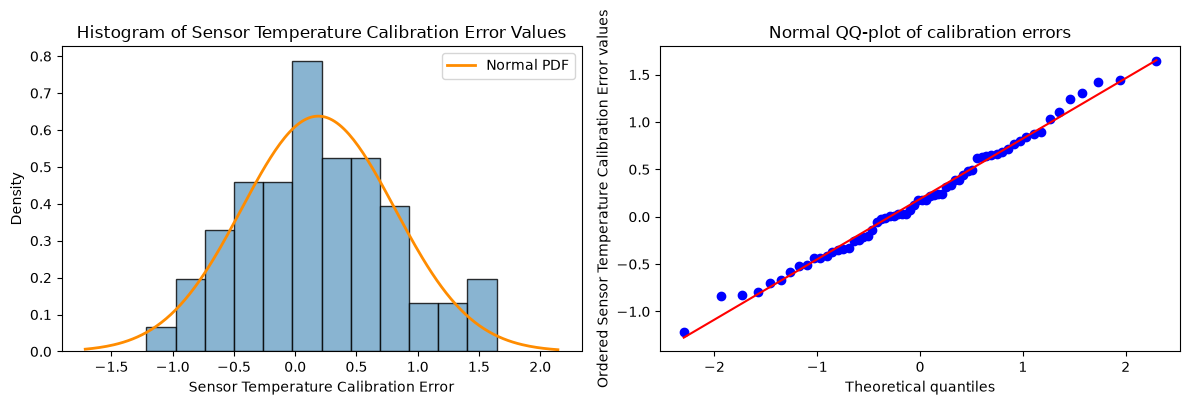

In [168]:
# Kristian

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
xs = np.linspace(x.min()-0.5, x.max()+0.5, 200)
axes[0].hist(x, bins=12, density=True, edgecolor="black", color="#6CA2C6", alpha=0.8)
axes[0].plot(xs, stats.norm(loc=xbar, scale=s).pdf(xs), color="#FF8C00", lw=2, label="Normal PDF")
axes[0].set_title("Histogram of Sensor Temperature Calibration Error Values")
axes[0].set_xlabel("Sensor Temperature Calibration Error")
axes[0].set_ylabel("Density")
axes[0].legend()
probplot(x, plot=axes[1])
axes[1].set_title("Normal QQ-plot of calibration errors")
axes[1].set_xlabel("Theoretical quantiles")
axes[1].set_ylabel("Ordered Sensor Temperature Calibration Error values")
plt.tight_layout()
plt.show()

From chapter 6.3. in the course book (p. 102), we know that one-sample t-intervals are exact under i.i.d. (independent and identically distributed) normal sampling - and for non-normal populations it is commonly used as an approximation when:
1. Sample mean is approximately normal.
2. Sample standard deviation estimates the population spread adequately.
3. Additionally, the quality of the approximation is influenced negatively by:
    - Strong skew.
    - Heavy Tails.
    - Influential outliers.
    - Dependence and process drift.

#### Discussion: Is a one-sample t interval reasonable?
To evaluate whether a one-sample t interval is reasonable, we need to look at how well our sample aligns with the requirements for using t-intervals presented above.

- For the histogram we see that the data forms one primary "hump" and is roughly symmetric around its center. We also see that values are quite tight (i.e. there are no extreme values far from the rest of the values). This is also visible in the QQ-plot: neither end has isolated points far from the line, which means that there are no apparent outliers. Using the values from 2.1, the interval $\bar x \pm 3s = 0.188 \pm 3 \cdot 0.626 \approx [-1.69,\ 2.07]$ contains all observations. A normal distribution would contain 99.7% within 3 standard deviations of its mean; the histogram shows values from about $-1.2$ to $1.6$.

- For the QQ plot we see that the dots (sample data) form an approximate straight line, with a slight wiggle near each end. For a completely normal distribution we should expect all values to line up close to a straight line, with only small randon deviations. Here we see them on an approximately straight line. A trend showing curvature (up/down) across multiple values would be an indicator that the sample is not approximately normally distributed.

**Requirement 1: Is the sample mean approximately normal?**
We only have one sample and therefore only one $\bar x$, so this cannot be seen directly in the plots. Instead, we can use the central limit theorem, which says that for i.i.d. observations with finite variance, $\bar X \approx N\!\left(\mu, \frac{\sigma^2}{n}\right)$, with estimated standard error $s/\sqrt{n} = 0.078$, that we computed in 2.1. How large $n$ must be, depends on the population shape: *"A symmetric, light-tailed population can produce an approximately normal mean for a modest n"* (course book, p. 89). The plots above show this type of shape, meaning that with $n = 64$ the CLT approximation appears to be good.

**Requirement 2: Does $s$ estimate the population spread adequately?**
Since $s$ is based on squared distances from the mean, a few extreme values or heavy tails would inflate it. In the QQ-plot, heavy tails would show as both ends bending away from the line (course book, p. 80). We see here that the ends only deviate slightly from the line, and no observations lie far from the rest. All observations also lie within $\bar x \pm 3s$ (see above). We therefore consider $s = 0.626$ a reasonable estimate of the population spread.

**Based on the above, a one-sample t interval seems reasonable** - of course under the assumption the observations are independent, which we elaborate upon in the paragraph below.

<br><br>

#### Discussion: Why plots cannot establish independence:
Plots do not say anything about how data was collected. It does not say if these sensors are all connected, are all located in the exact same measurement environment, etc. and if they potentially can influence each other. Consider the case where the sensor used to collect the reference temperature used to calibrate all the sensors in this sample was faulty - that would mean every sensor was not independent as they share the common reference sensor. Here, the assignment states that the sensors were *independently selected*, which is the basis for treating the observations as independent and for using $\widehat{\mathrm{SE}}(\bar X) = s/\sqrt{n}$. Here the plots help evaluate skew, heavy tails and outliers from point 3, but not dependence and drift.

<br><br>
### 2.3 Construct a 95% $t$ interval by calculating the degrees of freedom, critical value, standard error, and margin of error. Verify it with SciPy and interpret both the interval and the 95% confidence level correctly.

The course book (6.3 page 101) defines the statistic T for an unknown population standard deviation (i.e. $\sigma$ is unknown), under normal sampling with:

$$
T = \frac{\bar{X} - \mu}{S / \sqrt{n}} \sim t_{n-1}
$$

For observed data, theorem 6.2 makes this definition:

$$
\bar{x} \pm t_{n-1,\, 1-\alpha/2} \frac{s}{\sqrt{n}}
$$

From the latter, we can therefor define the 95% t interval for a mean with an unknown $\sigma$, which is the case in this task, to be between endpoints defined by:

$$
\bar{x} \pm t_{64-1,\, 1-0.05/2} \frac{0.626}{\sqrt{64}} = 0.188 \pm t_{64-1,\, 0.975} \frac{0.626}{8}
$$

We could use a T-table to determine the t value of the 0.975 quantile of a Student t with 64-1 degrees of freedom - but the tables provided in this course have degrees of freedom of 60 as the nearest exact value, so we will instead compute it using t.ppf.

In [169]:
# Kristian
dof_t = n - 1
print(f"degrees of freedom                        = {dof_t}")

t_critical_value = t.ppf(0.975, dof_t)
print(f"t critical value w. {dof_t} degrees of freedom = {t_critical_value:.3f}")

print(f"standard error                            = {se:.3f}")

margin_of_error = t_critical_value * se
print(f"margin of error                           = {margin_of_error:.3f}")

confidence_interval_low_end = xbar - margin_of_error
confidence_interval_high_end = xbar + margin_of_error

print(f"95% t-interval                            = [{confidence_interval_low_end:.3f}, {confidence_interval_high_end:.3f}]")

# Checking with scipy:
# Note that this uses scale as the standard error (not as s) and we just pass the 0.95 directly.
confidence_interval_scipy = t.interval(0.95, dof_t, loc=xbar, scale=se)
print(f"SciPy check                               = [{confidence_interval_scipy[0]:.3f}, {confidence_interval_scipy[1]:.3f}]")

degrees of freedom                        = 63
t critical value w. 63 degrees of freedom = 1.998
standard error                            = 0.078
margin of error                           = 0.156
95% t-interval                            = [0.032, 0.345]
SciPy check                               = [0.032, 0.345]


The SciPy check aligns with the calculated result.

**Interpreting the interval:** We have 64 sensors in our sample. We found that the 95% t interval for the population mean calibration error $\mu$ is $[0.032, 0.345]$.
This is the interval within which *mean* error of *all sensors* will plausibly fall within. This is *not* where individual sensors will plausibly fall within - which was -1.2 to 1.6 as seen on the histogram in 2.2.

**Interpreting the 95% confidence level:** $\mu$ for the population is an unknown, but fixed, number. It will either lie within $[0.032, 0.345]$, or not. It is the interval itself (endpoints) that change, depending on the sample used in the specific procedure (Course book, p. 99). Based on what we have computed here, we cannot say that $\mu$ lies in the identified interval with 0.95 probability. What this describes is the *procedure*, i.e. if we repeat the study many times using new samples of 64 sensors enough times we will end up seeing that about 95% of the intervals we construct using this approach, will contain $\mu$, given the assumptions discussed in 2.2.

<br><br>
### 2.4 Create a table of 90%, 95%, and 99% $t$ intervals and widths. Explain the confidence–precision trade-off.

In [170]:
# Kristian
# 90% Confidence interval
print("Computing the 90% confidence interval")
t_critical_value_90 = t.ppf(1 - (0.1/2), dof_t)
print(f"t critical t_({dof_t}, 0.95)                   = {t_critical_value_90:.3f}")

margin_of_error_t_90 = t_critical_value_90 * se
print(f"margin of error (t 0.90)                  = {margin_of_error_t_90:.3f}")

confidence_interval_t_90_low_end = xbar - margin_of_error_t_90
confidence_interval_t_90_high_end = xbar + margin_of_error_t_90

print(f"90% t-interval                            = [{confidence_interval_t_90_low_end:.3f}, {confidence_interval_t_90_high_end:.3f}]")

# Checking with scipy:
# Note that this uses scale as the standard error (not as s) and we just pass the 0.90 directly.
confidence_interval_scipy = t.interval(0.90, dof_t, loc=xbar, scale=se)
print(f"SciPy check (t 0.90)                      = [{confidence_interval_scipy[0]:.3f}, {confidence_interval_scipy[1]:.3f}]")

# 95% Confidence interval
# Already computed in 2.3.
print("\nThe 95% confidence interval (from 2.3)")
print(f"95% t-interval                            = [{confidence_interval_low_end:.3f}, {confidence_interval_high_end:.3f}]")


# 99% Confidence interval
print("\nComputing the 99% confidence interval")
t_critical_value_99 = t.ppf(1 - (0.01/2), dof_t)
print(f"t critical t_({dof_t}, 0.995)                  = {t_critical_value_99:.3f}")

margin_of_error_t_99 = t_critical_value_99 * se
print(f"margin of error (t 0.99)                  = {margin_of_error_t_99:.3f}")

confidence_interval_t_99_low_end = xbar - margin_of_error_t_99
confidence_interval_t_99_high_end = xbar + margin_of_error_t_99

print(f"99% t-interval                            = [{confidence_interval_t_99_low_end:.3f}, {confidence_interval_t_99_high_end:.3f}]")

# Checking with scipy:
# Note that this uses scale as the standard error (not as s) and we just pass the 0.99 directly.
confidence_interval_scipy = t.interval(0.99, dof_t, loc=xbar, scale=se)
print(f"SciPy check (t 0.99)                      = [{confidence_interval_scipy[0]:.3f}, {confidence_interval_scipy[1]:.3f}]\n\n")

# With the above calculations made, I had Claude Opus generate the following table - recalculating values as needed, since this can be easily verified against the value above.
print(f"Combining these into a table:")
rows = []
for level in (0.90, 0.95, 0.99):
    q = 1 - (1 - level) / 2                 # 0.95, 0.975, 0.995
    t_crit = t.ppf(q, dof_t)
    moe = t_crit * se
    lo, hi = xbar - moe, xbar + moe
    rows.append({"confidence level": f"{level:.0%}", "quantile q": q,
                 "t_(63, q)": t_crit, "margin of error": moe,
                 "lower": lo, "upper": hi, "width": 2 * moe})
pd.DataFrame(rows).round(3)

Computing the 90% confidence interval
t critical t_(63, 0.95)                   = 1.669
margin of error (t 0.90)                  = 0.131
90% t-interval                            = [0.058, 0.319]
SciPy check (t 0.90)                      = [0.058, 0.319]

The 95% confidence interval (from 2.3)
95% t-interval                            = [0.032, 0.345]

Computing the 99% confidence interval
t critical t_(63, 0.995)                  = 2.656
margin of error (t 0.99)                  = 0.208
99% t-interval                            = [-0.019, 0.396]
SciPy check (t 0.99)                      = [-0.019, 0.396]


Combining these into a table:


,confidence level,quantile q,"t_(63, q)",margin of error,lower,upper,width
0,90%,0.950,1.669,0.131,0.058,0.319,0.261
1,95%,0.975,1.998,0.156,0.032,0.345,0.313
2,99%,0.995,2.656,0.208,-0.019,0.396,0.416


We see clearly that as the confidence level increases (going from 90% to 99%), the width of the interval also increases. A higher confidence level requires the procedure to catch the fixed, unknown $\mu$ in a larger share of repeated samples (measured over many repetitions of the procedure) - so the interval must be wider.

We see this in the formula itself, where the t critical value grows from 1.669 at 90% confidence to 2.656 at 99% confidence. But the Standard Error $se$ remains the same across all the computed confidence intervals. Therefor the margin of error increases as confidence level increases (since moe = t_critical_value * se), which in turn applies a wider spread to the endpoints of the interval (since endpoints = xbar +/- moe).

As we demand a higher confidence level (i.e. a procedure that catches $\mu$ more often), we must accept a lower precision, since the interval itself becomes wider.

If we wanted both higher confidence **and** higher precision, we would need to add more independent observations as that would decrease the standard error $s/\sqrt{n}$.

<br><br>
### 2.5 Using $s$ as a planning value and the normal critical value, find the smallest approximate sample size for a 95% margin of error no larger than $0.10\ ^\circ\mathrm C$.

The Course Book chapter 6.3 p. 102, defines that if we have either $\sigma$ or a credible planning value, the margin of error of a two-sided z-interval is given by:

$$
E = z_{1-\alpha/2} \frac{\sigma}{\sqrt{n}}
$$

Solving for $n$ gives

$$
n \geq \left( \frac{z_{1-\alpha/2} \sigma}{E} \right)^2
$$

Since we don't know $\sigma$ but we do know that $s$ is our planning value, we can use $s$ in place of $\sigma$.

The course book makes it clear that we must always **round up** when calculating the value, because rounding down would exceed the target margin of error.

The value we are missing, is the $z_{1-0.05/2}$, or $z_{0.975}$.

We read this from our z-table to be $z_{0.975} = 1.960$.

In [171]:
# Kristian
# s was also calculated in 2.1
z_normal_critical_value = 1.960
target_margin_of_error = 0.1
s = x.std(ddof=1)

smallest_sample_size = ((z_normal_critical_value * s)/target_margin_of_error) ** 2

print(f"Smallest approximate sample size for a 95% margin of error, no larger than 0.10 sensor calibration temperature error:\n    {smallest_sample_size:.3f} sensors")

Smallest approximate sample size for a 95% margin of error, no larger than 0.10 sensor calibration temperature error:
    150.421 sensors


While the precise number of observations required is a decimal value, we must **round up** to avoid exceeding the target margin of error - since more independent observations increases precision as discussed in 2.4.

The smallest approximate sample size for a 95% margin of error no larger than 0.10 temperature units, is therefor **151 independent observations**.

<br><br>

### 2.6 With seed 2026 and at least 10,000 resamples, construct a percentile bootstrap interval. Compare it with the $t$ interval and state what the comparison cannot validate.

By "percentile bootstrap interval", we here assume the task asks for a 95% percentile bootstrap interval, that we then compare with the 95% t interval.

A Bootstrap sample is drawn with replacement from the actually observed values.

In [172]:
# Kristian
boot = bootstrap(
    (x,),
    np.mean,
    confidence_level=0.95,
    n_resamples=10000,
    method="percentile",
    random_state=np.random.default_rng(2026),
)
print(f"bootstrap 95% percentile interval = [{boot.confidence_interval.low:.3f}, {boot.confidence_interval.high:.3f}]")
print(f"95% t-interval (from 2.3)         = [{confidence_interval_low_end:.3f}, {confidence_interval_high_end:.3f}]")


bootstrap 95% percentile interval = [0.041, 0.341]
95% t-interval (from 2.3)         = [0.032, 0.345]


We see that the 95% percentile bootstrap interval lies quite close to the 95% t-interval.

Width of the 95% percentile interval is $0.341 - 0.041 = 0.300$, while the width of the 95% t-interval is $0.345 - 0.032 = 0.313$.

That's a minor difference of $0.013$.

Since the bootstrap approximates the sampling variation by resampling the observed data instead of using the $t$ distribution (course book, ch 6.5, p. 106), it acts as a computational check of our $t$ interval. The very minor difference indicates that the $t$ interval is consistent with the sampling variation seen in our own data. The bootstrap does **not** create new information, beyond what is already observed. It cannot be used to validate or repair bias in the data or lack of independence in the observations - so it is affected by these same limitations as the t-intervals themselves. Both intervals, after all, come from the same 64 observations - so they would be affected by the same data collection issues.

<br><br><br>

---

<br>

## Part 3: Estimating a false-rejection proportion

The file [assignment03_access_control.csv](./data/assignment03_access_control.csv) contains 240 independently staged legitimate login attempts. `false_reject` equals 1 when a legitimate attempt was rejected and 0 otherwise. Let $p$ be the population false-rejection probability under the test conditions.

<br><br>
### 3.1 Report $n$, the number of false rejections $x$, and $\hat p$. Explain why $\hat p$ is also the sample mean of a binary variable.

In [173]:
# TODO: Katrine

<br><br>
### 3.2 Construct and interpret a 95% Wilson interval for $p$ with statsmodels. State the population and parameter clearly.

In [174]:
# TODO: Katrine

<br><br><br>
### 3.3 Calculate the 95% Wald interval from its formula. Compare it with Wilson and explain why Wilson is the preferred default.

In [175]:
# TODO: Katrine

<br><br>
### 3.4 Create a table of 90%, 95%, and 99% Wilson intervals and widths.

In [176]:
# TODO: Kristian

<br><br>
### 3.5 Estimate the sample size for a 95% margin of error no larger than 0.02 using first $p=0.5$ and then the observed $\hat p$. Round up and explain the difference.

In [177]:
# TODO: Kristian

<br><br><br>

---

<br>

## Part 4: AI-Use and Conclusion
### AI-use
> State which AI tools you used, what they contributed, what you changed or rejected, and how you verified the work. A short paragraph or table is sufficient. If AI produced most of the code or text, state this honestly.

#### In part 1 - [AI tool and model]
`Assigned to: ___`
- *TODO: what the AI contributed*
##### What changed/got rejected:
- *TODO*
##### How we checked that the final work was correct:
- *TODO*
<br><br>

#### In part 2 - Claude Opus 5.5
`Assigned to: Kristian`
- Tasks were solved manually first, using the course tutorials, notes and course book as reference.
- AI was used as a sparring partner - asked to elaborate and help explain principles and concepts.
- It was used as a reviewer, being fed the initial solved versions of the tasks and asked to provide concrete feedback on the solutions.
- It was also use to help with the markdown latex syntax for math formulas.

##### What changed/got rejected:
- Textual discussions and interpretations were adjusted based on the provided feedback. Certain points were made clearer.
- I initially calculated 2.4 by "hand" and wrote the table in markdown. The AI reviewer rightfully pointed out that the assignment states that tables should be generated by code - so I had it generate the table in code.
- In 2.5 I mistakenly used the t-critical value in place of the z-value, despite the text asking for the normal critical value (z). AI review caught it, so I got the chance to change that.

##### How we checked that the final work was correct:
- SciPy's built-in functions were used to check the work.
- AI was also asked to check the results we computed - although not 100% for such a task, the intent was to get the feedback in case it AI by chance identified an issue in the computed results.
<br><br>

#### In part 3 - [AI tool and model]
`Assigned to: ___`
- *TODO: what the AI contributed*
##### What changed/got rejected:
- *TODO*
##### How we checked that the final work was correct:
- *TODO*
<br><br>

_____________

### Overall conclusion
> Write approximately 150–250 words explaining how sample size and sampling variability affect sample means, standard errors, and confidence-interval precision. Report the two parameter estimates with uncertainty and state one design limitation for each study.
>
> Only use Sessions 5–6. Do not perform hypothesis tests or use methods from later sessions.

*TODO*


## Submission Checklist

- [ ] Sampling distributions are distinguished from populations and observed samples.
- [ ] Standard error is distinguished from standard deviation.
- [ ] Exact normal sampling and the CLT approximation are distinguished.
- [ ] The $t$ interval is used because population $\sigma$ is unknown.
- [ ] Wilson is the primary proportion interval.
- [ ] Confidence levels use repeated-sampling interpretation.
- [ ] Bootstrap and planning calculations are reproducible.
- [ ] Part 4 contains AI-use and conclusion.
- [ ] All code is executed and output is visible.